# Salvador Cardoso — Week 09: Student final grades (G3)
## Question: What can we predict about a student's final mathematics grade?

This notebook examines G3 using earlier grades G1/G2 and other habits. The previous-term grades are strong predictors but are **not causal explanations**. The models are evaluated on a held-out test split. Based on the CUNY Tech Prep Week 09 syllabus.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

## 1. Read the student-performance dataset
The mathematics CSV is semicolon-delimited. If you have a local copy, it takes priority; otherwise the notebook downloads the same public UCI dataset mirror used by the class lecture.

In [2]:
from pathlib import Path
local_candidates = [Path("student-mat.csv"), Path("data/student-mat.csv"), Path("../data/student-mat.csv")]
local_path = next((p for p in local_candidates if p.exists()), None)
url = "https://raw.githubusercontent.com/rupakc/UCI-Data-Analysis/master/Student%20Dataset/Student/student-mat.csv"
students = pd.read_csv(local_path if local_path is not None else url, sep=";")
print("Rows, columns:", students.shape)
display(students[["G1", "G2", "G3", "studytime", "failures", "absences"]].describe().round(2))
print("Missing values:", students.isna().sum().sum())

Rows, columns: (395, 33)


,G1,G2,G3,studytime,failures,absences
count,395.00,395.00,395.00,395.00,395.00,395.00
mean,10.91,10.71,10.42,2.04,0.33,5.71
std,3.32,3.76,4.58,0.84,0.74,8.00
min,3.00,0.00,0.00,1.00,0.00,0.00
25%,8.00,9.00,8.00,1.00,0.00,0.00
50%,11.00,11.00,11.00,2.00,0.00,4.00
75%,13.00,13.00,14.00,2.00,0.00,8.00
max,19.00,19.00,20.00,4.00,3.00,75.00


Missing values: 0


## 2. Investigate a pattern
Evaluate final grade across earlier grade groups and failures. These are associations; they do not demonstrate that changing a feature will change the final grade.

,count,mean,median
failures,,,
0,312,11.25,11.0
1,50,8.12,9.0
2,17,6.24,8.0
3,16,5.69,7.0


G3           1.000
G2           0.905
G1           0.801
studytime    0.098
absences     0.034
failures    -0.360
Name: G3, dtype: float64

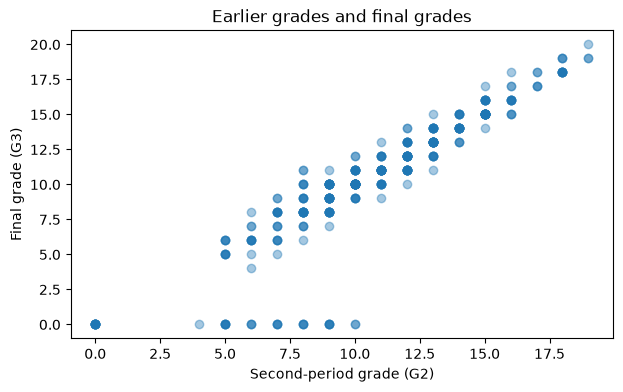

In [3]:
display(students.groupby("failures")["G3"].agg(["count","mean","median"]).round(2))
display(students[["G1","G2","G3","studytime","failures","absences"]].corr(numeric_only=True)["G3"].sort_values(ascending=False).round(3))
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(students["G2"], students["G3"], alpha=0.4)
ax.set(xlabel="Second-period grade (G2)", ylabel="Final grade (G3)", title="Earlier grades and final grades")
plt.show()

## 3. Compare a small tree and a forest
Include G1/G2 to predict the final grade late in the term, rather than claiming the model can predict the grade at enrollment.

In [4]:
features = ["G1", "G2", "studytime", "failures", "absences", "goout", "freetime"]
X, y = students[features], students["G3"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
tree_model = DecisionTreeRegressor(max_depth=3, random_state=42)
forest_model = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=42, n_jobs=-1)
results = []
for name, model in [("Decision tree", tree_model), ("Random forest", forest_model)]:
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({"model": name, "test_R2": r2_score(y_test, pred),
                    "test_MAE": mean_absolute_error(y_test, pred),
                    "test_RMSE": np.sqrt(mean_squared_error(y_test, pred))})
display(pd.DataFrame(results).round(3))
print("Any R² > 0.9?", any(r["test_R2"] > 0.9 for r in results))

,model,test_R2,test_MAE,test_RMSE
0,Decision tree,0.771,1.310,2.169
1,Random forest,0.843,1.128,1.797


Any R² > 0.9? False


## 4. Interpret the predictions carefully

In [5]:
pi = permutation_importance(forest_model, X_test, y_test, n_repeats=15, random_state=42, scoring="r2")
importance = pd.Series(pi.importances_mean, index=features).sort_values(ascending=False)
display(importance.to_frame("Mean decrease in held-out R²").round(3))
print("Most predictive feature in this model:", importance.index[0])

,Mean decrease in held-out R²
G2,1.623
absences,0.137
studytime,0.008
failures,0.005
freetime,0.001
G1,-0.002
goout,-0.003


Most predictive feature in this model: G2


### Conclusions

- Comparing G2 with G3 tests whether recent performance is associated with final grades, not whether it causes them.
- G1 and G2 make the model suitable for **late-term** prediction; removing them tests whether study habits alone are informative.
- Review the **held-out R²**, MAE and permutation-importance results above before writing a numerical conclusion. A score above 0.9 is **not guaranteed**, and it must not be reported unless actually observed.
- This analysis is exploratory and cannot justify individual student interventions without further validation.